# Prediksi Risiko Stroke Berdasarkan Indikator Medis dan Gaya Hidup

## 1. Business & Data Understanding
### 1.1 Latar Belakang & Tujuan
Stroke merupakan penyebab utama kematian dan disabilitas jangka panjang. Deteksi dini risiko stroke berdasarkan indikator klinis dan gaya hidup diperlukan untuk membantu fasilitas kesehatan melakukan penapisan (*screening*) preventif. Tujuan proyek ini adalah membangun model klasifikasi untuk memprediksi risiko stroke pada pasien dengan memaksimalkan sensitivitas deteksi (*Recall*) agar meminimalkan kasus berisiko yang terlewat (*False Negative*).

### 1.2 Sumber Data & Lisensi
* **Nama Dataset**: Stroke Prediction Dataset (`healthcare-dataset-stroke-data.csv`)
* **Sumber**: Kaggle (diunggah oleh *fedesoriano*)
* **Lisensi**: Data Publik (CC0 / Public Domain) untuk keperluan riset dan edukasi.
* **Dimensi**: 5.110 baris dan 12 kolom.

### 1.3 Data Dictionary
| Nama Variabel | Tipe Data | Satuan / Kategori | Keterangan |
| :--- | :--- | :--- | :--- |
| `id` | Numerik (int) | ID Unik | Nomor identitas pasien (non-prediktif) |
| `gender` | Kategorikal | Male, Female, Other | Jenis kelamin pasien |
| `age` | Numerik (float) | Tahun | Usia pasien (rentang 0.08 – 82 tahun) |
| `hypertension` | Biner (int) | 0 = Tidak, 1 = Ya | Riwayat tekanan darah tinggi |
| `heart_disease` | Biner (int) | 0 = Tidak, 1 = Ya | Riwayat penyakit jantung |
| `ever_married` | Kategorikal | Yes, No | Status pernikahan |
| `work_type` | Kategorikal | Private, Self-employed, Govt_job, children, Never_worked | Jenis pekerjaan |
| `Residence_type` | Kategorikal | Urban, Rural | Tipe wilayah tempat tinggal |
| `avg_glucose_level` | Numerik (float) | mg/dL | Rata-rata kadar glukosa dalam darah |
| `bmi` | Numerik (float) | kg/m² | Indeks Massa Tubuh (*Body Mass Index*) |
| `smoking_status` | Kategorikal | formerly smoked, never smoked, smokes, Unknown | Status merokok pasien |
| `stroke` | Biner (Target) | 0 = Tidak Stroke, 1 = Stroke | Status riwayat stroke pasien |

### 1.4 Representativitas & Bias Sampel
1. **Ketidakseimbangan Kelas (*Class Imbalance*)**: Hanya **4,87%** (249 dari 5.110 pasien) yang berstatus `stroke = 1`, sedangkan **95,13%** (4.861 pasien) berstatus `stroke = 0`.
2. **Bias Pencatatan (*Missingness Bias*)**: Nilai `bmi` kosong sebanyak 201 baris (3,93%), tetapi proporsi kekosongan pada pasien stroke mencapai **16,06%** (jauh lebih tinggi dibanding non-stroke yang hanya **3,31%**). Hal ini mengindikasikan kondisi darurat medis membuat pengukuran berat/tinggi badan sering terlewat saat pasien masuk rumah sakit.
3. **Kategori `Unknown` pada Riwayat Merokok**: Sebanyak 1.544 pasien (30,2%) memiliki status merokok `Unknown` (didominasi kelompok usia anak-anak atau pasien yang tidak terdata riwayatnya).

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Library Preprocessing & Feature Selection (Standard Scikit-Learn)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import mutual_info_classif

sns.set_theme(style="whitegrid")

# Memuat dataset
df = pd.read_csv('healthcare-dataset-stroke-data.csv')
print(f"Dimensi Dataset Awal: {df.shape[0]} baris, {df.shape[1]} kolom")
display(df.head())

Dimensi Dataset Awal: 5110 baris, 12 kolom


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


## 2. Audit Kualitas Data & Statistik Deskriptif
Tahap ini memeriksa tipe data, statistik deskriptif, duplikasi baris, *missing values*, dan deteksi *outlier* menggunakan metode Interquartile Range (IQR) sebelum dilakukan pembersihan data.

In [3]:
# 1. Informasi struktur tipe data
print("=== Informasi Tipe Data ===")
df.info()

# 2. Statistik Deskriptif
print("\n=== Statistik Deskriptif Fitur Numerik ===")
display(df.describe().T)

print("\n=== Statistik Deskriptif Fitur Kategorikal ===")
display(df.describe(include='object').T)

# 3. Audit Duplikasi & Missing Values
print(f"\nJumlah Baris Duplikat: {df.duplicated().sum()}")

missing_df = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing (%)': (df.isnull().sum() / len(df)) * 100
})
print("\n=== Audit Missing Values ===")
display(missing_df[missing_df['Missing Count'] > 0])

# Cek proporsi missing BMI berdasarkan status stroke
print("=== Proporsi Missing BMI per Kelas Target ===")
display(df.groupby('stroke')['bmi'].apply(lambda x: f"{x.isnull().sum()} ({x.isnull().mean()*100:.2f}%)"))

# 4. Audit Outlier dengan Metode IQR
num_features = ['age', 'avg_glucose_level', 'bmi']
outlier_summary = []

for col in num_features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    outlier_summary.append({
        'Fitur': col,
        'Batas Bawah': round(lower_bound, 2),
        'Batas Atas': round(upper_bound, 2),
        'Jumlah Outlier': len(outliers),
        'Persentase (%)': round(len(outliers) / len(df) * 100, 2)
    })

print("\n=== Audit Outlier (Metode IQR) ===")
display(pd.DataFrame(outlier_summary))

# 5. Cek kategori minoritas/anomali pada fitur kategorikal
print("\n=== Distribusi Kategori Gender ===")
print(df['gender'].value_counts())

=== Informasi Tipe Data ===
<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 634.7 KB

=== Statistik Deskriptif Fitur Numerik ===


,count,mean,std,min,25%,50%,75%,max
id,5110.0,36517.829354,21161.721625,67.00,17741.250,36932.000,54682.00,72940.00
age,5110.0,43.226614,22.612647,0.08,25.000,45.000,61.00,82.00
hypertension,5110.0,0.097456,0.296607,0.00,0.000,0.000,0.00,1.00
heart_disease,5110.0,0.054012,0.226063,0.00,0.000,0.000,0.00,1.00
avg_glucose_level,5110.0,106.147677,45.283560,55.12,77.245,91.885,114.09,271.74
bmi,4909.0,28.893237,7.854067,10.30,23.500,28.100,33.10,97.60
stroke,5110.0,0.048728,0.215320,0.00,0.000,0.000,0.00,1.00



=== Statistik Deskriptif Fitur Kategorikal ===


,count,unique,top,freq
gender,5110,3,Female,2994
ever_married,5110,2,Yes,3353
work_type,5110,5,Private,2925
Residence_type,5110,2,Urban,2596
smoking_status,5110,4,never smoked,1892



Jumlah Baris Duplikat: 0

=== Audit Missing Values ===


,Missing Count,Missing (%)
bmi,201,3.933464


=== Proporsi Missing BMI per Kelas Target ===


stroke
0    161 (3.31%)
1    40 (16.06%)
Name: bmi, dtype: str


=== Audit Outlier (Metode IQR) ===


,Fitur,Batas Bawah,Batas Atas,Jumlah Outlier,Persentase (%)
0,age,-29.00,115.00,0,0.00
1,avg_glucose_level,21.98,169.36,627,12.27
2,bmi,9.10,47.50,110,2.15



=== Distribusi Kategori Gender ===
gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64


## 3. Exploratory Data Analysis (EDA) & Visualisasi
Visualisasi dilakukan untuk memahami distribusi target, perbedaan karakteristik klinis antara pasien stroke dan non-stroke, serta hubungan korelasi antar variabel.

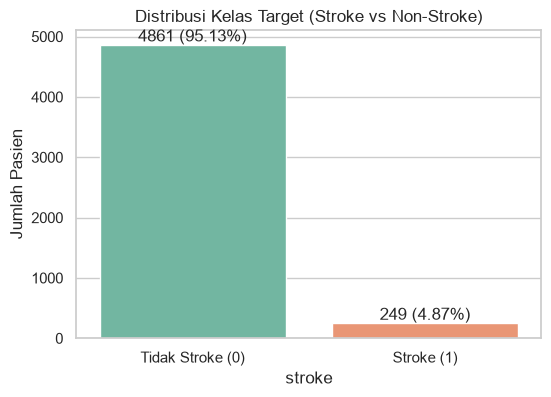

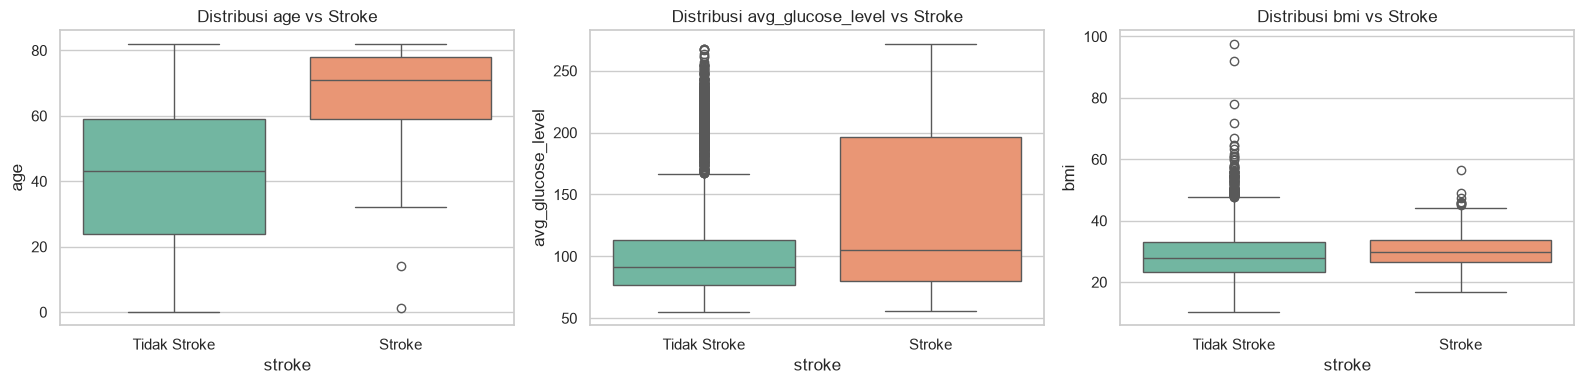

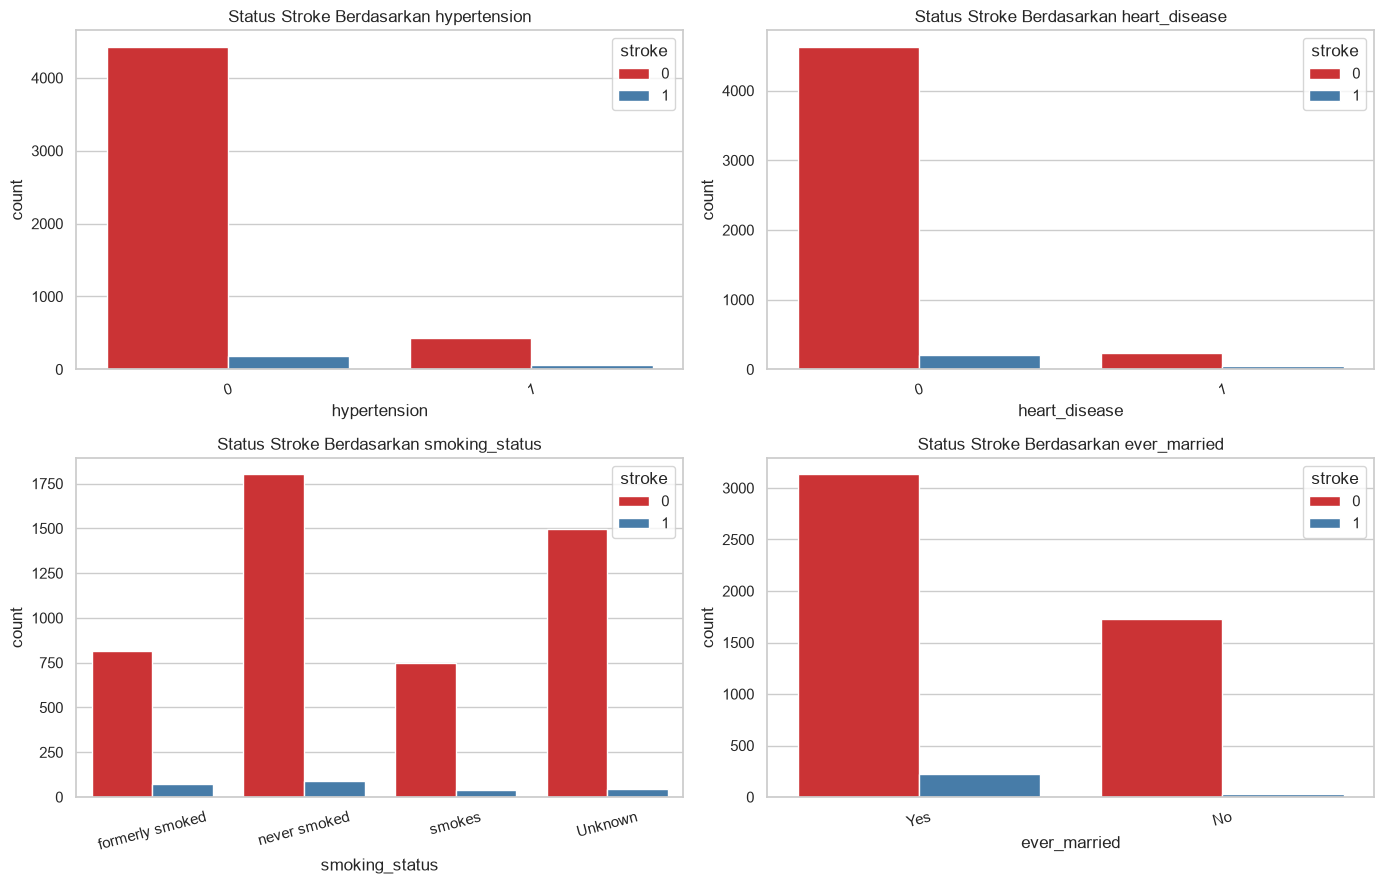

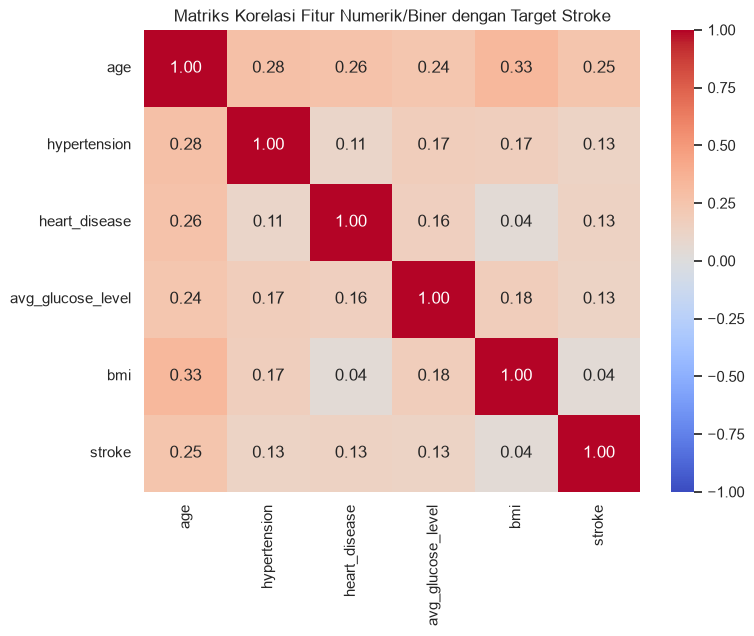

In [4]:
# 1. Visualisasi Distribusi Kelas Target (Imbalance)
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x='stroke', hue='stroke', palette='Set2', legend=False)
plt.title('Distribusi Kelas Target (Stroke vs Non-Stroke)')
plt.xticks([0, 1], ['Tidak Stroke (0)', 'Stroke (1)'])
plt.ylabel('Jumlah Pasien')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())} ({p.get_height()/len(df)*100:.2f}%)',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom')
plt.show()

# 2. Boxplot Fitur Numerik vs Status Stroke
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for idx, col in enumerate(num_features):
    sns.boxplot(data=df, x='stroke', y=col, hue='stroke', ax=axes[idx], palette='Set2', legend=False)
    axes[idx].set_title(f'Distribusi {col} vs Stroke')
    axes[idx].set_xticks([0, 1])
    axes[idx].set_xticklabels(['Tidak Stroke', 'Stroke'])
plt.tight_layout()
plt.show()

# 3. Proporsi Stroke pada Fitur Kategorikal & Biner Utama
cat_key = ['hypertension', 'heart_disease', 'smoking_status', 'ever_married']
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()
for idx, col in enumerate(cat_key):
    sns.countplot(data=df, x=col, hue='stroke', ax=axes[idx], palette='Set1')
    axes[idx].set_title(f'Status Stroke Berdasarkan {col}')
    axes[idx].tick_params(axis='x', rotation=15)
plt.tight_layout()
plt.show()

# 4. Heatmap Korelasi Antar Fitur Numerik/Biner dan Target
plt.figure(figsize=(8, 6))
corr_cols = ['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi', 'stroke']
sns.heatmap(df[corr_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Matriks Korelasi Fitur Numerik/Biner dengan Target Stroke')
plt.show()

### 3.1 Kesimpulan & Insight Utama EDA
1. **Insight 1  Missing Value `bmi` Terkonsentrasi pada Pasien Stroke (Keputusan Imputasi Median)**:
   * Nilai `bmi` yang hilang mencapai 16,06% pada pasien stroke dibanding 3,31% pada non-stroke, dan distribusinya menceng ke kanan (*right-skewed*). Baris kosong **tidak boleh dihapus** agar sampel kelas minoritas (`stroke = 1`) tidak berkurang drastis. Strategi yang dipilih adalah **imputasi menggunakan Median** karena tahan terhadap nilai ekstrem.
2. **Insight 2 Outlier Klinis pada Glukosa & BMI Bersifat Valid (Keputusan Retensi Outlier)**:
   * Ditemukan 12,27% *outlier* pada `avg_glucose_level` dan 2,15% pada `bmi`. Secara medis, kadar glukosa tinggi (>200 mg/dL) merepresentasikan kondisi diabetes yang merupakan faktor risiko nyata penyakit stroke, bukan kesalahan pencatatan. Oleh karena itu, *outlier* numerik **dipertahankan** dan akan ditangani skalanya menggunakan `StandardScaler`. Satu-satunya data yang dihapus adalah 1 baris `gender == 'Other'` (0,02%) karena tidak representatif secara statistik.
3. **Insight 3 Dominasi Faktor Usia & Ketimpangan Kelas (Keputusan Stratified Split & Class Weight)**:
   * Korelasi positif tertinggi terhadap `stroke` ditunjukkan oleh `age` ($r = 0,25$; median usia pasien stroke **71 tahun** vs non-stroke **43 tahun**), diikuti `heart_disease` ($r = 0,13$), `avg_glucose_level` ($r = 0,13$), dan `hypertension` ($r = 0,13$). Karena rasio kelas sangat timpang (95,13% vs 4,87%), pembagian data wajib menggunakan **`stratify=y`** agar proporsi kelas terjaga, serta penanganan ketimpangan kelas dilakukan melalui penyesuaian bobot kelas (**`class_weight='balanced'`**) dan **Random Oversampling** bawaan `pandas`/`sklearn` tanpa menambah data sintetis buatan.

## 4. Data Cleaning (Perbandingan Sebelum vs Sesudah)
Pada tahap ini dilakukan pembersihan awal:
1. Menghapus kolom `id` karena hanya merupakan identitas acak pasien.
2. Menghapus 1 baris dengan kategori `gender == 'Other'` agar variabel gender konsisten biner (`Male` / `Female`).
3. Menangani *missing values* pada `bmi` (imputasi median akan diterapkan di dalam *pipeline* setelah *splitting* untuk mencegah *data leakage*, namun di bawah ini ditampilkan simulasi hasil pembersihan secara keseluruhan sebagai verifikasi kualitas data).

In [5]:
# Simpan ringkasan sebelum cleaning
before_summary = {
    'Jumlah Baris': df.shape[0],
    'Jumlah Kolom': df.shape[1],
    'Missing Values (bmi)': df['bmi'].isnull().sum(),
    'Jumlah Duplikat': df.duplicated().sum(),
    'Kategori Gender': str(df['gender'].value_counts().to_dict())
}

# Proses Cleaning struktural
df_clean = df.drop(columns=['id']).copy()
df_clean = df_clean[df_clean['gender'] != 'Other'].reset_index(drop=True)

# Verifikasi hasil imputasi median (untuk perbandingan before-after)
df_after_check = df_clean.copy()
median_bmi_val = df_after_check['bmi'].median()
df_after_check['bmi'] = df_after_check['bmi'].fillna(median_bmi_val)

after_summary = {
    'Jumlah Baris': df_after_check.shape[0],
    'Jumlah Kolom': df_after_check.shape[1],
    'Missing Values (bmi)': df_after_check['bmi'].isnull().sum(),
    'Jumlah Duplikat': df_after_check.duplicated().sum(),
    'Kategori Gender': str(df_after_check['gender'].value_counts().to_dict())
}

comparison_df = pd.DataFrame({'Sebelum Cleaning': before_summary, 'Sesudah Cleaning': after_summary})
print("=== Perbandingan Kondisi Dataset Sebelum vs Sesudah Cleaning ===")
display(comparison_df)

=== Perbandingan Kondisi Dataset Sebelum vs Sesudah Cleaning ===


,Sebelum Cleaning,Sesudah Cleaning
Jumlah Baris,5110,5109
Jumlah Kolom,12,11
Missing Values (bmi),201,0
Jumlah Duplikat,0,0
Kategori Gender,"{'Female': 2994, 'Male': 2115, 'Other': 1}","{'Female': 2994, 'Male': 2115}"


## 5. Data Preprocessing, Feature Selection & Penanganan Imbalance
### 5.1 Alasan Teknik Preprocessing yang Dipilih
* **Train-Test Split (80:20) dengan `stratify=y`**: Dilakukan **sebelum** imputasi dan *scaling* untuk mencegah *data leakage* (kebocoran informasi statistik data uji ke data latih), sekaligus menjaga proporsi kelas stroke (~4,87%) tetap identik di data latih dan data uji.
* **Imputasi Median & `StandardScaler`**: Diterapkan pada fitur numerik (`age`, `avg_glucose_level`, `bmi`) agar distribusi fitur berada pada skala rata-rata 0 dan standar deviasi 1.
* **One-Hot Encoding (`OneHotEncoder`)**: Diterapkan pada fitur kategorikal nominal (`gender`, `ever_married`, `work_type`, `Residence_type`, `smoking_status`) agar algoritma tidak mengasumsikan urutan tingkatan antar kategori.
* **Feature Selection**: Kolom `id` dibuang karena tidak memiliki daya prediksi. Seluruh 10 fitur klinis dan demografis lainnya dievaluasi relevansinya menggunakan skor **Mutual Information**.
* **Penanganan Imbalance (Random Oversampling / Class Weight)**: Tanpa menggunakan data sintetis (seperti SMOTE), penyeimbangan data latih dilakukan dengan **Random Oversampling** menggunakan `pandas.sample()` (menggandakan sampel kelas minoritas secara acak hanya pada `X_train` agar distribusi 50:50) serta didukung parameter **`class_weight='balanced'`** saat pemodelan nanti.

Shape X_train setelah encoding & scaling : (4087, 20)
Shape X_test setelah encoding & scaling  : (1022, 20)


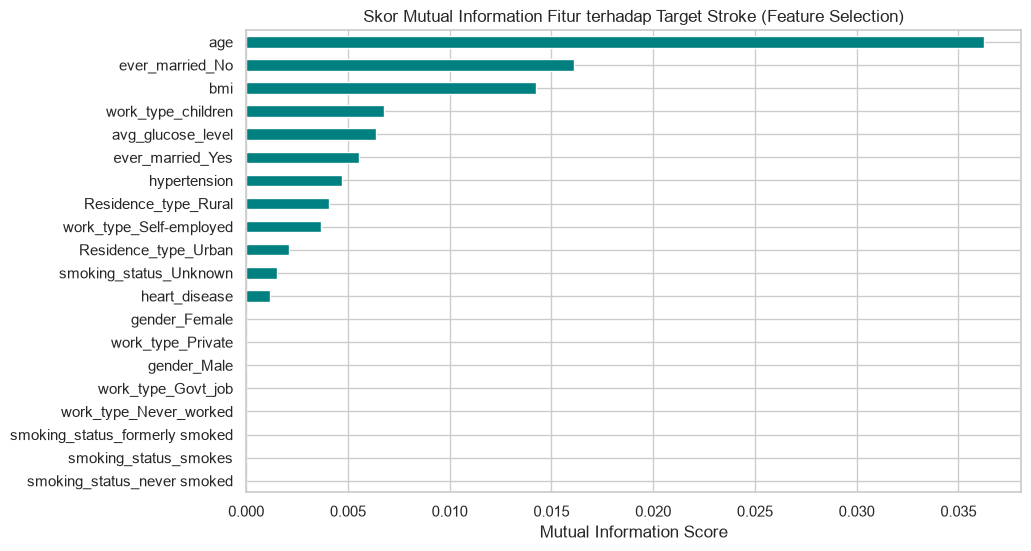


=== Distribusi Kelas Target Data Train (Sebelum vs Sesudah Random Oversampling) ===


,Sebelum Balancing,Sesudah Random Oversampling
stroke,,
0,3888,3888
1,199,3888


,age,avg_glucose_level,bmi,gender_Female,gender_Male,ever_married_No,ever_married_Yes,work_type_Govt_job,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_Unknown,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,hypertension,heart_disease
0,1.269492,-1.088283,-0.639911,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,-1.734111,-0.568934,-1.441292,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0
2,-1.822453,0.082042,-1.609323,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,0.960298,-0.110028,-0.084115,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,0.165226,0.097488,1.996889,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0


In [6]:
# 1. Pemisahan Fitur (X) dan Target (y) dari df_clean
X = df_clean.drop(columns=['stroke'])
y = df_clean['stroke']

# 2. Train-Test Split (80:20) dengan Stratify
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 3. Definisi Pipeline Preprocessing
num_cols = ['age', 'avg_glucose_level', 'bmi']
cat_cols = ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']
binary_cols = ['hypertension', 'heart_disease']

num_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols),
    ('passthrough', 'passthrough', binary_cols)
])

# Fit pada train, transform pada train & test
X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)

# Konversi kembali ke DataFrame dengan nama kolom lengkap
cat_encoder = preprocessor.named_transformers_['cat'].named_steps['encoder']
encoded_cat_cols = list(cat_encoder.get_feature_names_out(cat_cols))
all_feature_names = num_cols + encoded_cat_cols + binary_cols

X_train_df = pd.DataFrame(X_train_prepared, columns=all_feature_names)
X_test_df = pd.DataFrame(X_test_prepared, columns=all_feature_names)

print(f"Shape X_train setelah encoding & scaling : {X_train_df.shape}")
print(f"Shape X_test setelah encoding & scaling  : {X_test_df.shape}")

# 4. Feature Selection: Evaluasi Kepentingan Fitur dengan Mutual Information
mi_scores = mutual_info_classif(X_train_df, y_train, random_state=42)
mi_series = pd.Series(mi_scores, index=X_train_df.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
mi_series.plot(kind='barh', color='teal')
plt.gca().invert_yaxis()
plt.title('Skor Mutual Information Fitur terhadap Target Stroke (Feature Selection)')
plt.xlabel('Mutual Information Score')
plt.show()

# 5. Penanganan Class Imbalance dengan Random Oversampling (Bawaan Pandas - Hanya pada Data Train)
train_combined = X_train_df.copy()
train_combined['stroke'] = y_train.values

df_majority = train_combined[train_combined['stroke'] == 0]
df_minority = train_combined[train_combined['stroke'] == 1]

# Oversampling kelas minoritas agar seimbang dengan kelas mayoritas
df_minority_upsampled = df_minority.sample(n=len(df_majority), replace=True, random_state=42)
train_balanced = pd.concat([df_majority, df_minority_upsampled]).sample(frac=1, random_state=42).reset_index(drop=True)

X_train_balanced = train_balanced.drop(columns=['stroke'])
y_train_balanced = train_balanced['stroke']

print("\n=== Distribusi Kelas Target Data Train (Sebelum vs Sesudah Random Oversampling) ===")
imbalance_comp = pd.DataFrame({
    'Sebelum Balancing': y_train.value_counts(),
    'Sesudah Random Oversampling': y_train_balanced.value_counts()
})
display(imbalance_comp)
display(X_train_balanced.head())

### 5.2 Keputusan Akhir Feature Selection
* **Fitur Dibuang**: `id` (identifier acak tanpa informasi medis, berisiko menimbulkan *overfitting*).
* **Fitur Dipertahankan (10 Variabel Awal $\rightarrow$ 20 Kolom Hasil One-Hot Encoding)**: Berdasarkan hasil visualisasi *Mutual Information* dan domain medis, fitur utama seperti `age`, `avg_glucose_level`, `hypertension`, `heart_disease`, `ever_married`, dan `bmi` memiliki kontribusi informasi yang jelas terhadap variabel target. Seluruh 20 fitur hasil transformasi dipertahankan untuk tahap pemodelan berikutnya serta dapat dievaluasi lebih lanjut menggunakan *feature importance* berbasis model.

## 6. Visualisasi Tambahan: Audit dan Sebelum vs Sesudah Cleaning
Statistik deskriptif lengkap (termasuk median), missing bmi per kelas, distribusi bmi sebelum/sesudah imputasi median, dan persentase outlier IQR.

                    count    mean    std    min  median     max
age                5110.0   43.23  22.61   0.08   45.00   82.00
avg_glucose_level  5110.0  106.15  45.28  55.12   91.88  271.74
bmi                4909.0   28.89   7.85  10.30   28.10   97.60


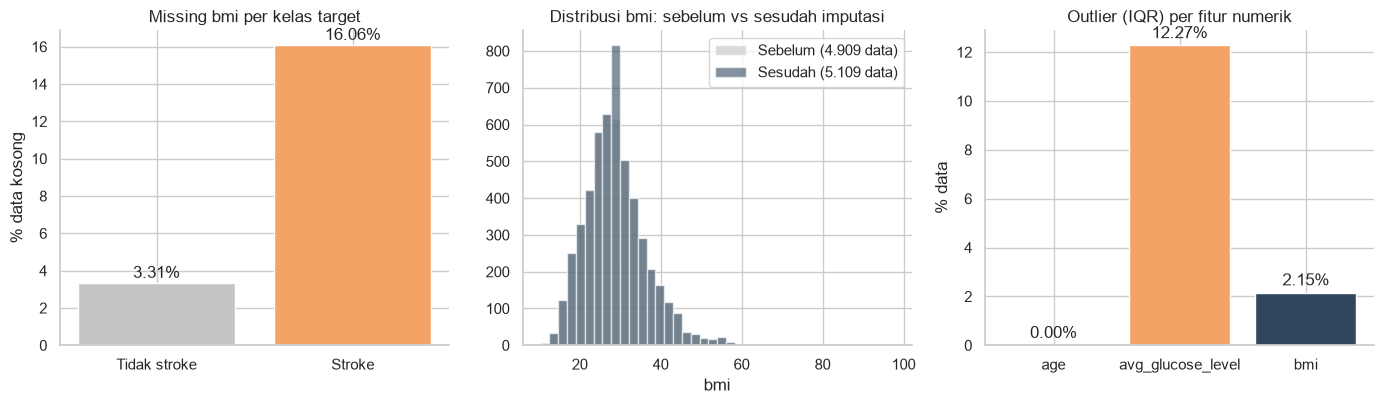

In [7]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
df = pd.read_csv('healthcare-dataset-stroke-data.csv')
NAVY, ORG, GREY = '#30475E', '#F2A365', '#C4C4C4'

# Statistik deskriptif lengkap (termasuk median)
num = ['age', 'avg_glucose_level', 'bmi']
desc = df[num].agg(['count', 'mean', 'std', 'min', 'median', 'max']).T
print(desc.round(2))

# Data bersih (id & gender Other dibuang, bmi diimputasi median)
df_clean = df.drop(columns=['id']); df_clean = df_clean[df_clean['gender'] != 'Other']
bmi_after = df_clean['bmi'].fillna(df_clean['bmi'].median())

fig, ax = plt.subplots(1, 3, figsize=(14, 4.2))
# (a) Missing bmi per kelas target
miss = df.groupby('stroke')['bmi'].apply(lambda s: s.isnull().mean() * 100)
b = ax[0].bar(['Tidak stroke', 'Stroke'], miss.values, color=[GREY, ORG])
for r, v in zip(b, miss.values): ax[0].text(r.get_x() + r.get_width()/2, v + 0.3, f'{v:.2f}%', ha='center')
ax[0].set_title('Missing bmi per kelas target'); ax[0].set_ylabel('% data kosong')
# (b) Distribusi bmi sebelum vs sesudah imputasi median
ax[1].hist(df['bmi'].dropna(), bins=40, alpha=.6, color=GREY, label='Sebelum (4.909 data)')
ax[1].hist(bmi_after, bins=40, alpha=.6, color=NAVY, label='Sesudah (5.109 data)')
ax[1].set_title('Distribusi bmi: sebelum vs sesudah imputasi'); ax[1].set_xlabel('bmi'); ax[1].legend()
# (c) Persentase outlier IQR per fitur numerik
pct = []
for c in num:
    q1, q3 = df[c].quantile([.25, .75]); i = q3 - q1
    pct.append(((df[c] < q1 - 1.5*i) | (df[c] > q3 + 1.5*i)).mean() * 100)
b = ax[2].bar(['age', 'avg_glucose_level', 'bmi'], pct, color=[GREY, ORG, NAVY])
for r, v in zip(b, pct): ax[2].text(r.get_x() + r.get_width()/2, v + 0.3, f'{v:.2f}%', ha='center')
ax[2].set_title('Outlier (IQR) per fitur numerik'); ax[2].set_ylabel('% data')
for a in ax: a.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()


## 7. Pemodelan

Bagian ini melatih model memakai **data train hasil Progress 2** (`X_train_df`, `y_train`, serta `X_train_balanced`, `y_train_balanced`) dan mengevaluasinya pada data uji (`X_test_df`, `y_test`) yang tidak pernah dipakai saat training maupun pemilihan parameter.

### 7.1 Pemilihan Model dan Alasannya

Tujuan di Business Understanding: memetakan **tingkat risiko stroke** dengan **recall setinggi mungkin** (kasus berisiko yang terlewat harus sesedikit mungkin). Data: tabular, 5.109 baris, 20 fitur hasil encoding, kelas sangat timpang (4,87% stroke). Tiga model dari materi praktikum dipilih karena masing-masing menjawab sisi yang berbeda:

| No | Model | Alasan cocok dengan data dan tujuan | Parameter yang diatur |
| :-: | :--- | :--- | :--- |
| 1 | **Logistic Regression** | Model linear yang stabil untuk data tabular berukuran kecil, koefisiennya mudah dibaca secara klinis, dan menghasilkan **probabilitas risiko** yang dipakai untuk membentuk segmen risiko (rendah, sedang, tinggi). | `C` (kekuatan regularisasi) |
| 2 | **Decision Tree** | Menangkap hubungan non-linear dan interaksi antar faktor (misalnya usia tua digabung hipertensi) dan menghasilkan aturan *if-then* yang mudah dijelaskan ke tenaga kesehatan. | `max_depth` (kedalaman pohon) |
| 3 | **K-Nearest Neighbors (KNN)** | Menilai risiko seorang pasien dari pasien-pasien yang profilnya paling mirip, sejalan dengan gagasan segmentasi berbasis kemiripan. Fitur sudah distandarisasi sehingga jarak antar fitur sebanding. | `n_neighbors` (nilai k) |

Sebagai pembanding ditambahkan **DummyClassifier** (selalu menebak kelas mayoritas). Ia bukan kandidat model, hanya patokan: model yang dibuat harus lebih baik dari tebakan tanpa pembelajaran.

**Metrik** (sesuai Business Understanding): *Recall* sebagai metrik utama, dilengkapi *Precision*, *F1*, **F2** (menekankan recall dua kali lipat dibanding precision), ROC-AUC, dan PR-AUC. *Accuracy* hanya ditampilkan sebagai pelengkap karena menyesatkan pada data timpang.

**Cara memilih parameter**: setiap parameter dicoba pada beberapa nilai dengan **Stratified 5-Fold Cross-Validation pada data train**, lalu dipilih nilai dengan **rata-rata F2** tertinggi. F2 dipilih (bukan recall saja) karena recall murni bisa dicapai secara curang dengan menebak semua pasien berisiko. F2 tetap mengutamakan recall tetapi menghukum model yang terlalu banyak salah alarm.

In [8]:
# === 7.2 Persiapan: import, random_state, dan fungsi bantu ===
import warnings
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             precision_recall_curve, ConfusionMatrixDisplay)
warnings.filterwarnings('ignore')

# random_state tunggal dipakai di semua proses acak agar hasil identik setiap kali notebook dijalankan ulang
RANDOM_STATE = 42

# Indeks X_train_df berupa RangeIndex, sedangkan y_train membawa indeks asli. Disamakan agar aman dipotong bersama.
y_train_r = y_train.reset_index(drop=True)
y_test_r = y_test.reset_index(drop=True)

def oversample(X, y, seed=RANDOM_STATE):
    # Random oversampling kelas minoritas (sama dengan Progress 2). Dipakai di dalam setiap fold CV
    # supaya data validasi fold tidak ikut terduplikasi (mencegah kebocoran data).
    comb = X.copy(); comb['stroke'] = y.values
    maj = comb[comb['stroke'] == 0]
    mino = comb[comb['stroke'] == 1].sample(n=len(maj), replace=True, random_state=seed)
    comb = pd.concat([maj, mino]).sample(frac=1, random_state=seed).reset_index(drop=True)
    return comb.drop(columns='stroke'), comb['stroke']

def metrik(y_true, y_pred, y_prob):
    # Kumpulan metrik evaluasi sesuai Business Understanding (recall = metrik utama)
    return {
        'Recall': recall_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'F1': f1_score(y_true, y_pred),
        'F2': fbeta_score(y_true, y_pred, beta=2),
        'ROC-AUC': roc_auc_score(y_true, y_prob),
        'PR-AUC': average_precision_score(y_true, y_prob),
        'Accuracy': accuracy_score(y_true, y_pred),
    }

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def cv_cari_parameter(buat_model, daftar_nilai, nama_param):
    # Mencoba setiap nilai parameter dengan 5-fold CV; oversampling hanya pada bagian train tiap fold
    baris = []
    for nilai in daftar_nilai:
        f2, rc, pr = [], [], []
        for idx_a, idx_v in skf.split(X_train_df, y_train_r):
            Xa, ya = oversample(X_train_df.iloc[idx_a], y_train_r.iloc[idx_a])
            model = buat_model(nilai).fit(Xa, ya)
            pred = model.predict(X_train_df.iloc[idx_v])
            f2.append(fbeta_score(y_train_r.iloc[idx_v], pred, beta=2))
            rc.append(recall_score(y_train_r.iloc[idx_v], pred))
            pr.append(precision_score(y_train_r.iloc[idx_v], pred, zero_division=0))
        baris.append({nama_param: nilai, 'F2 (CV)': np.mean(f2), 'Recall (CV)': np.mean(rc), 'Precision (CV)': np.mean(pr)})
    return pd.DataFrame(baris)

print('Persiapan selesai. random_state =', RANDOM_STATE)

Persiapan selesai. random_state = 42


### 7.3 Pemilihan Nilai Parameter (Cross-Validation pada Data Train)

Setiap model dicoba pada rentang nilai parameter. Rentang dibuat dari yang sangat sederhana sampai yang sangat kompleks agar terlihat titik di mana model mulai *underfit* atau *overfit*.

=== Logistic Regression: hasil CV per nilai C ===


,C,F2 (CV),Recall (CV),Precision (CV)
0,0.001,0.4003,0.8390,0.1296
1,0.010,0.4021,0.8088,0.1336
2,0.100,0.4078,0.8091,0.1367
3,1.000,0.4080,0.8091,0.1369
4,10.000,0.4062,0.8041,0.1364
5,100.000,0.4062,0.8041,0.1364


-> Parameter terbaik (F2 CV tertinggi): C = 1.0

=== Decision Tree: hasil CV per nilai max_depth ===


,max_depth,F2 (CV),Recall (CV),Precision (CV)
0,2,0.3575,0.9599,0.1019
1,3,0.3800,0.7533,0.1295
2,4,0.3627,0.7833,0.1174
3,5,0.3392,0.6991,0.1123
4,6,0.3014,0.5776,0.1037
5,8,0.2898,0.4823,0.1121
6,10,0.2856,0.4173,0.1263
7,15,0.1875,0.2062,0.1433


-> Parameter terbaik (F2 CV tertinggi): max_depth = 3

=== KNN: hasil CV per nilai n_neighbors ===


,n_neighbors,F2 (CV),Recall (CV),Precision (CV)
0,3,0.1421,0.1655,0.0910
1,5,0.1847,0.2410,0.0956
2,7,0.2447,0.3568,0.1086
3,11,0.2792,0.4723,0.1061
4,15,0.3033,0.5727,0.1054
5,21,0.3218,0.6683,0.1047
6,31,0.3266,0.7236,0.1023
7,51,0.3490,0.7487,0.1114
8,71,0.3505,0.7537,0.1117
9,101,0.3778,0.8241,0.1195


-> Parameter terbaik (F2 CV tertinggi): n_neighbors = 101



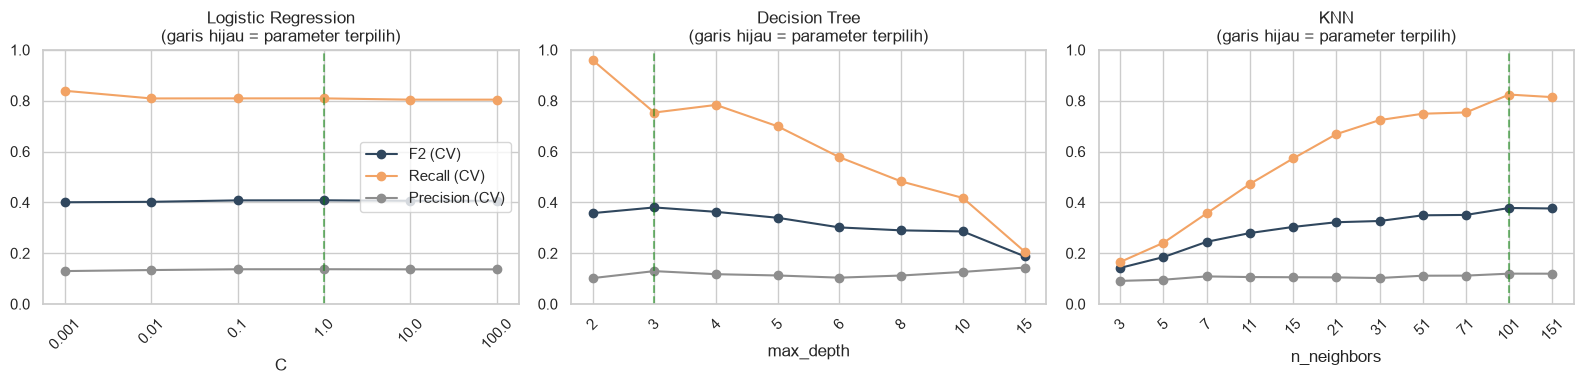

In [9]:
# === 7.3 Pencarian parameter terbaik dengan Stratified 5-Fold CV ===
konfigurasi = {
    'Logistic Regression': dict(
        buat=lambda c: LogisticRegression(C=c, max_iter=1000, random_state=RANDOM_STATE),
        nilai=[0.001, 0.01, 0.1, 1, 10, 100], param='C'),
    'Decision Tree': dict(
        buat=lambda d: DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE),
        nilai=[2, 3, 4, 5, 6, 8, 10, 15], param='max_depth'),
    'KNN': dict(
        buat=lambda k: KNeighborsClassifier(n_neighbors=k),
        nilai=[3, 5, 7, 11, 15, 21, 31, 51, 71, 101, 151], param='n_neighbors'),
}

hasil_cv, parameter_terbaik = {}, {}
for nama, cfg in konfigurasi.items():
    tabel = cv_cari_parameter(cfg['buat'], cfg['nilai'], cfg['param'])
    hasil_cv[nama] = tabel
    parameter_terbaik[nama] = tabel.loc[tabel['F2 (CV)'].idxmax(), cfg['param']]
    print(f"=== {nama}: hasil CV per nilai {cfg['param']} ===")
    display(tabel.round(4))
    print(f"-> Parameter terbaik (F2 CV tertinggi): {cfg['param']} = {parameter_terbaik[nama]}\n")

# Visualisasi: F2, Recall, dan Precision (CV) terhadap nilai parameter
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (nama, cfg) in zip(axes, konfigurasi.items()):
    t = hasil_cv[nama]; x = range(len(t))
    for kolom, warna in [('F2 (CV)', '#30475E'), ('Recall (CV)', '#F2A365'), ('Precision (CV)', '#8E8E8E')]:
        ax.plot(x, t[kolom], marker='o', label=kolom, color=warna)
    ax.set_xticks(list(x)); ax.set_xticklabels(t[cfg['param']].astype(str), rotation=45)
    ax.axvline(list(t[cfg['param']]).index(parameter_terbaik[nama]), ls='--', color='green', alpha=.5)
    ax.set_title(f"{nama}\n(garis hijau = parameter terpilih)"); ax.set_xlabel(cfg['param']); ax.set_ylim(0, 1)
axes[0].legend(loc='center right'); plt.tight_layout(); plt.show()

### 7.4 Training Model Akhir dan Evaluasi pada Data Uji

Model dilatih ulang pada **seluruh data train yang sudah di-oversample** (`X_train_balanced`, `y_train_balanced` dari Progress 2) dengan parameter terbaik hasil CV, lalu diuji **satu kali** pada data uji asli (tanpa oversampling, proporsi stroke tetap 4,9%).

=== Tabel Perbandingan Model pada Data Uji (1.022 pasien, 50 kasus stroke) ===


,Recall,Precision,F1,F2,ROC-AUC,PR-AUC,Accuracy
Model,,,,,,,
Dummy (patokan),0.00,0.0000,0.0000,0.0000,0.5000,0.0489,0.9511
Logistic Regression,0.80,0.1338,0.2292,0.4008,0.8384,0.2666,0.7368
Decision Tree,0.84,0.1047,0.1863,0.3494,0.8208,0.1831,0.6409
KNN,0.80,0.1187,0.2067,0.3724,0.8145,0.1909,0.6996


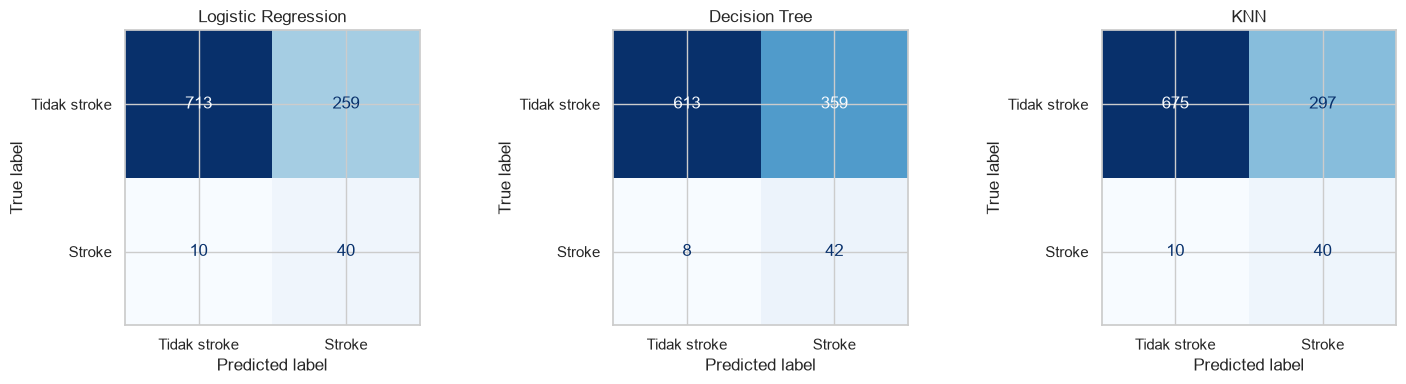

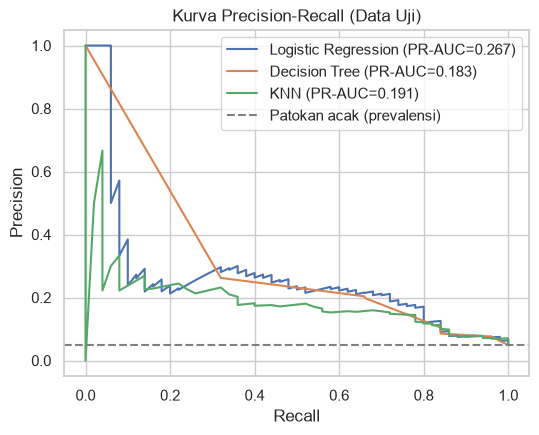

In [10]:
# === 7.4 Training akhir + evaluasi pada data uji ===
model_final = {
    'Dummy (patokan)': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression': LogisticRegression(C=parameter_terbaik['Logistic Regression'], max_iter=1000, random_state=RANDOM_STATE),
    'Decision Tree': DecisionTreeClassifier(max_depth=int(parameter_terbaik['Decision Tree']), random_state=RANDOM_STATE),
    'KNN': KNeighborsClassifier(n_neighbors=int(parameter_terbaik['KNN'])),
}

baris_hasil, prob_test, pred_test = [], {}, {}
for nama, model in model_final.items():
    model.fit(X_train_balanced, y_train_balanced)              # training pada data train (sudah seimbang)
    pred = model.predict(X_test_df)                            # prediksi kelas pada data uji
    prob = model.predict_proba(X_test_df)[:, 1]                # probabilitas stroke (dipakai ROC/PR-AUC dan segmentasi)
    pred_test[nama], prob_test[nama] = pred, prob
    baris_hasil.append({'Model': nama, **metrik(y_test_r, pred, prob)})

tabel_banding = pd.DataFrame(baris_hasil).set_index('Model')
print('=== Tabel Perbandingan Model pada Data Uji (1.022 pasien, 50 kasus stroke) ===')
display(tabel_banding.round(4))

# Confusion matrix tiap model
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, nama in zip(axes, ['Logistic Regression', 'Decision Tree', 'KNN']):
    ConfusionMatrixDisplay(confusion_matrix(y_test_r, pred_test[nama]),
                           display_labels=['Tidak stroke', 'Stroke']).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(nama)
plt.tight_layout(); plt.show()

# Kurva Precision-Recall
plt.figure(figsize=(6, 4.5))
for nama in ['Logistic Regression', 'Decision Tree', 'KNN']:
    p, r, _ = precision_recall_curve(y_test_r, prob_test[nama])
    plt.plot(r, p, label=f"{nama} (PR-AUC={average_precision_score(y_test_r, prob_test[nama]):.3f})")
plt.axhline(y_test_r.mean(), ls='--', color='grey', label='Patokan acak (prevalensi)')
plt.xlabel('Recall'); plt.ylabel('Precision'); plt.title('Kurva Precision-Recall (Data Uji)'); plt.legend(); plt.show()

### 7.5 Hasil Awal: Segmentasi Tingkat Risiko

Probabilitas stroke dari model terbaik dipecah menjadi tiga segmen risiko. **Batas segmen ditentukan dari data train** (prediksi *out-of-fold* hasil cross-validation), bukan dari data uji, lalu diterapkan ke data uji. Segmentasi dianggap bermakna jika persentase stroke sebenarnya **naik konsisten dari Rendah ke Tinggi** pada kedua data.

F2 (CV) terbaik per model: {'Logistic Regression': np.float64(0.408), 'Decision Tree': np.float64(0.38), 'KNN': np.float64(0.3778)}
Model dasar segmentasi: Logistic Regression

=== Segmen pada DATA TRAIN (prediksi out-of-fold) - dasar penentuan batas ===


,Jumlah_Pasien,Kasus_Stroke,Persen_Stroke,Persen_dari_Kasus_Stroke
segmen,,,,
Rendah,2907,38,1.31,19.10
Sedang,778,84,10.80,42.21
Tinggi,402,77,19.15,38.69


=== Segmen pada DATA UJI - hasil akhir ===


,Jumlah_Pasien,Kasus_Stroke,Persen_Stroke,Persen_dari_Kasus_Stroke
segmen,,,,
Rendah,723,10,1.38,20.0
Sedang,194,16,8.25,32.0
Tinggi,105,24,22.86,48.0



=== Profil rata-rata tiap segmen (data uji) ===


,age,avg_glucose_level,bmi,hypertension,heart_disease
segmen,,,,,
Rendah,32.38,96.51,28.26,0.03,0.01
Sedang,64.80,121.70,31.24,0.23,0.06
Tinggi,76.95,153.23,29.64,0.44,0.21


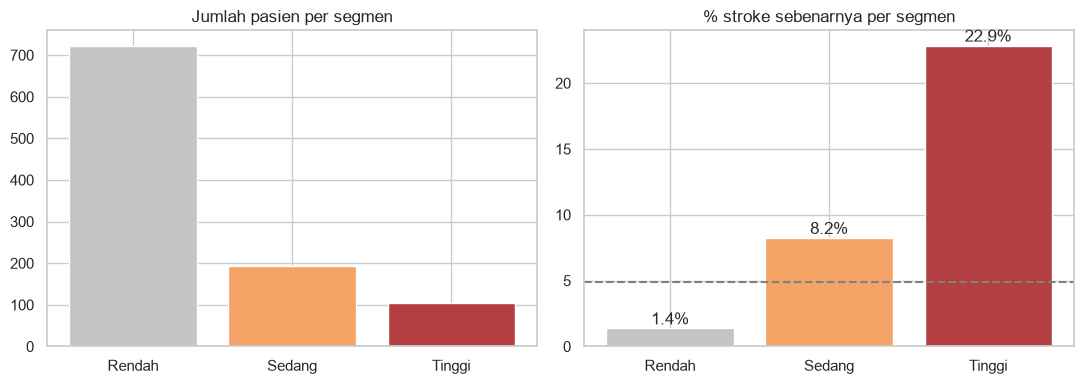

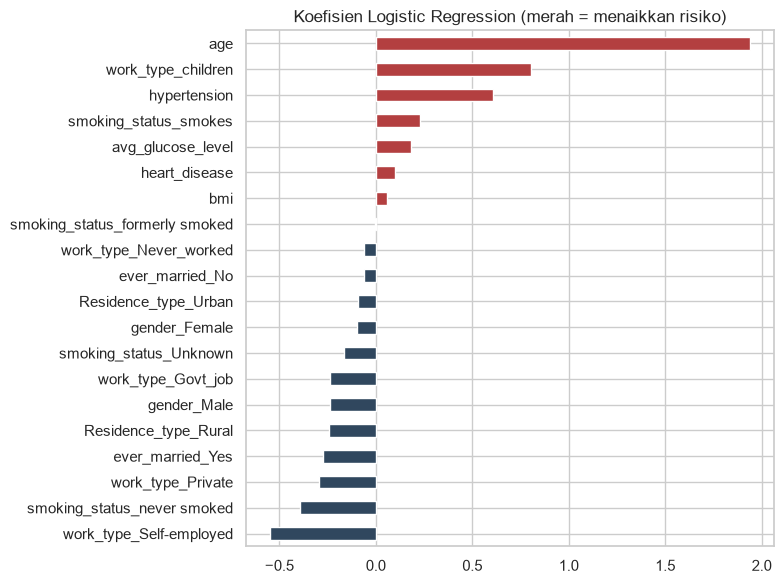

In [11]:
# === 7.5 Segmentasi tingkat risiko dari probabilitas model terbaik ===
# Model dasar dipilih dari F2 hasil cross-validation (bukan dari data uji, agar data uji tetap bersih)
f2_cv_terbaik = {n: t['F2 (CV)'].max() for n, t in hasil_cv.items()}
model_terbaik = max(f2_cv_terbaik, key=f2_cv_terbaik.get)
print('F2 (CV) terbaik per model:', {k: round(v, 4) for k, v in f2_cv_terbaik.items()})
print('Model dasar segmentasi:', model_terbaik)

# Probabilitas out-of-fold pada data train: tiap pasien diprediksi oleh model yang tidak pernah melihat dirinya
oof = np.zeros(len(X_train_df))
for idx_a, idx_v in skf.split(X_train_df, y_train_r):
    Xa, ya = oversample(X_train_df.iloc[idx_a], y_train_r.iloc[idx_a])
    m = konfigurasi[model_terbaik]['buat'](parameter_terbaik[model_terbaik]).fit(Xa, ya)
    oof[idx_v] = m.predict_proba(X_train_df.iloc[idx_v])[:, 1]

# Batas segmen. Model dilatih pada data seimbang 50:50, sehingga 0,5 = batas keputusan model.
# Batas 0,8 dipilih agar persentase stroke naik konsisten Rendah < Sedang < Tinggi pada data train (OOF).
BATAS = [0.5, 0.8]
LABEL = ['Rendah', 'Sedang', 'Tinggi']
def buat_segmen(p):
    return pd.cut(pd.Series(p), bins=[-0.01, BATAS[0], BATAS[1], 1.01], labels=LABEL)

def ringkas_segmen(segmen, y_true):
    r = pd.DataFrame({'segmen': segmen.values, 'stroke': np.asarray(y_true)}).groupby('segmen', observed=True)['stroke'] \
          .agg(Jumlah_Pasien='count', Kasus_Stroke='sum', Persen_Stroke=lambda s: s.mean() * 100)
    r['Persen_dari_Kasus_Stroke'] = r['Kasus_Stroke'] / r['Kasus_Stroke'].sum() * 100
    return r

print('\n=== Segmen pada DATA TRAIN (prediksi out-of-fold) - dasar penentuan batas ===')
display(ringkas_segmen(buat_segmen(oof), y_train_r).round(2))

prob = pd.Series(prob_test[model_terbaik])
segmen = buat_segmen(prob)
ringkas = ringkas_segmen(segmen, y_test_r)
print('=== Segmen pada DATA UJI - hasil akhir ===')
display(ringkas.round(2))

# Profil rata-rata fitur klinis per segmen (nilai asli, sebelum scaling)
profil = X_test.reset_index(drop=True).assign(segmen=segmen.values) \
    .groupby('segmen', observed=True)[['age', 'avg_glucose_level', 'bmi', 'hypertension', 'heart_disease']].mean()
print('\n=== Profil rata-rata tiap segmen (data uji) ===')
display(profil.round(2))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
warna = ['#C4C4C4', '#F2A365', '#B33F40']
ax[0].bar(ringkas.index.astype(str), ringkas['Jumlah_Pasien'], color=warna); ax[0].set_title('Jumlah pasien per segmen')
b = ax[1].bar(ringkas.index.astype(str), ringkas['Persen_Stroke'], color=warna); ax[1].set_title('% stroke sebenarnya per segmen')
for r_, v in zip(b, ringkas['Persen_Stroke']): ax[1].text(r_.get_x() + r_.get_width() / 2, v + 0.3, f'{v:.1f}%', ha='center')
ax[1].axhline(y_test_r.mean() * 100, ls='--', color='grey')
plt.tight_layout(); plt.show()

# Koefisien Logistic Regression: arah dan kekuatan pengaruh tiap fitur
koef = pd.Series(model_final['Logistic Regression'].coef_[0], index=X_train_df.columns).sort_values()
plt.figure(figsize=(8, 6)); koef.plot(kind='barh', color=['#B33F40' if v > 0 else '#30475E' for v in koef])
plt.title('Koefisien Logistic Regression (merah = menaikkan risiko)'); plt.tight_layout(); plt.show()

### 7.6 Arti Hasil Awal

**Perbandingan model (data uji, 1.022 pasien, 50 kasus stroke)**

* **Semua model jauh lebih baik dari patokan.** Dummy punya *accuracy* 95,1% tetapi *recall* 0% (tidak satu pun pasien stroke terdeteksi). Ini membuktikan accuracy tidak cocok sebagai metrik pada data timpang.
* **Logistic Regression adalah model terbaik secara keseluruhan.** *Recall* 0,80 (40 dari 50 kasus stroke terdeteksi), F2 0,401, ROC-AUC 0,838, dan PR-AUC 0,267 (sekitar 5,5 kali patokan acak 0,049). Ia juga unggul pada F2 hasil cross-validation (0,408 vs 0,380 untuk Decision Tree dan 0,378 untuk KNN).
* **Decision Tree** punya recall tertinggi (0,84) tetapi precision terendah (0,105), jadi lebih banyak salah alarm. **KNN** recall-nya sama dengan Logistic Regression (0,80) tetapi PR-AUC lebih rendah (0,191).
* **Selisih recall antar model kecil** (0,80 vs 0,84 setara dua pasien dari 50), sehingga perbedaan itu belum cukup kuat untuk menyatakan satu model unggul dari sisi recall saja. Pembeda yang lebih jelas ada pada F2, PR-AUC, dan precision.
* **Precision rendah (sekitar 0,10 - 0,13) adalah konsekuensi dari tujuan memaksimalkan recall** pada kasus yang hanya 4,9% dari populasi. Pada Logistic Regression, 259 pasien tidak stroke ikut ditandai berisiko untuk menangkap 40 kasus stroke. Untuk penapisan awal ini dapat diterima, tetapi bukan alat diagnosis.

**Pengaruh parameter (7.3)**

* **Decision Tree**: makin dalam pohonnya, recall turun tajam (0,96 pada `max_depth=2` menjadi 0,21 pada `max_depth=15`) karena pohon menghafal data latih (*overfitting*). Kedalaman 3 memberi F2 terbaik.
* **KNN**: k kecil memberi hasil buruk karena terlalu peka terhadap noise dan duplikat hasil oversampling. Performa naik sampai k sekitar 100 dan mendatar sesudahnya.
* **Logistic Regression**: hampir tidak sensitif terhadap `C` (F2 0,400 - 0,408), jadi modelnya stabil.

**Segmentasi tingkat risiko (7.5)**

| Segmen | Jumlah pasien uji | Kasus stroke | % stroke | Ciri rata-rata |
| :--- | :-: | :-: | :-: | :--- |
| Rendah | 723 | 10 | 1,4% | usia 32 tahun, glukosa 97 mg/dL, hipertensi 3% |
| Sedang | 194 | 16 | 8,2% | usia 65 tahun, glukosa 122 mg/dL, hipertensi 23% |
| Tinggi | 105 | 24 | 22,9% | usia 77 tahun, glukosa 153 mg/dL, hipertensi 44%, penyakit jantung 21% |

* Persentase stroke **naik konsisten** dari Rendah ke Tinggi, pada data train (1,3% - 10,8% - 19,2%) maupun data uji. Artinya segmentasi bermakna dan tidak hanya kebetulan pada satu data.
* Segmen Tinggi (10% pasien) memuat 48% kasus stroke, dan gabungan Sedang + Tinggi (29% pasien) memuat 80% kasus stroke. Pasien di segmen Tinggi sekitar 4,7 kali lebih berisiko dibanding rata-rata populasi (22,9% vs 4,9%).
* **Faktor pembeda utama** (koefisien Logistic Regression): usia paling dominan (1,94), disusul hipertensi (0,61), kadar glukosa (0,18), dan penyakit jantung (0,10). Ini sejalan dengan temuan EDA. Koefisien kolom hasil one-hot encoding (misalnya `work_type_children`) saling berkorelasi dengan usia sehingga tidak ditafsirkan terpisah.

**Keterbatasan hasil awal**

1. Data uji hanya berisi 50 kasus stroke, sehingga setiap metrik memiliki ketidakpastian cukup besar.
2. Label `stroke` berarti pasien **sudah pernah stroke**, bukan stroke di masa depan. Segmen Tinggi berarti "profilnya mirip pasien yang pernah stroke", bukan prediksi pasti.
3. Batas segmen (0,5 dan 0,8) dipilih berdasarkan data train dan masih dapat disesuaikan dengan kebutuhan klinis.
4. Pada tahap awal ini hanya tiga model dengan satu cara penanganan imbalance (random oversampling) yang dibandingkan. Perbandingan dengan `class_weight`, threshold tuning, dan model ensemble dapat menjadi langkah berikutnya.

In [12]:
# === 7.7 Uji reprodusibilitas: training ulang harus memberi prediksi yang persis sama ===
for nama in ['Logistic Regression', 'Decision Tree', 'KNN']:
    ulang = type(model_final[nama])(**model_final[nama].get_params()).fit(X_train_balanced, y_train_balanced)
    sama = np.array_equal(ulang.predict_proba(X_test_df)[:, 1], prob_test[nama])
    print(f'{nama:<22} hasil identik setelah training ulang: {sama}')
# Pada tingkat notebook, random_state=42 dipakai untuk split, oversampling, mutual information, CV, dan model.

Logistic Regression    hasil identik setelah training ulang: True
Decision Tree          hasil identik setelah training ulang: True
KNN                    hasil identik setelah training ulang: True
